# Density matrix exponentiation (DME) channel performance
The DME channel acts on the data qubit $\sigma$ as follows:
$$
\hat{E}_t^{(\rho)}(\sigma) = \text{Tr}_{1}\left[e^{-i t \text{SWAP}} (\rho\otimes\sigma) e^{i t \text{SWAP}}\right] \tag{1}
$$
where $t\in \mathbb R$ is the DME channel duration. 
Tthe DME channel transform the data registers into an approximation of the unitary $u_{\rho}=e^{-it\rho}$.

The following code will implement this channel on random data and instruction density matrix, and plot the norm $||e^{-it\rho}\sigma e^{it\rho} - \hat{E}_t^{(\rho)}(\sigma)||$

In [ ]:
import sys
sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 16
plt.rcParams['savefig.dpi'] = 75
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['legend.labelspacing'] = .3
plt.rcParams['legend.columnspacing']= .3
plt.rcParams['legend.handletextpad']= .1
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = "serif"
plt.rcParams['font.serif'] = "cm"
plt.rcParams["figure.figsize"] = [5, 3.50]
plt.rcParams["figure.autolayout"] = True

# Import dme functions from the 'function' folder
from functions.dme import *

In [ ]:
# Create random data and instruction state
t = 1
muq = 60

psi0 = np.random.rand(2) + 1j * np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T
data = psi0@psi0.conj().T
print(data)

psi0 = np.random.rand(2) + 1j * np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T
instruction = psi0@psi0.conj().T
print(instruction)

[[0.83132435+0.j         0.36346853+0.09008219j]
 [0.36346853-0.09008219j 0.16867565+0.j        ]]
[[0.41695277+0.j         0.49294895+0.01022222j]
 [0.49294895-0.01022222j 0.58304723+0.j        ]]


In [ ]:
# Calculate the expected density matrix, by applying the instruction unitary e^it\rho 
# on data register \sigma
expected_state = dme_expm(data,instruction,t,0)

In [ ]:
# Applying the DME channel on the data and instruction qubits
rho_W = []
rho_list = []
rho_W = []
rho_list = []
for M in range(1,muq):
    _rho_W,_rho_list = dme_channel(data,instruction,t,M)
    rho_W.append(_rho_W[-1])
    rho_list.append(_rho_list[-1])

In [43]:
# An equivalent expression of DME channel, using cos and sine expansion 
# and does not require partial trace
rho_W_channel_equivalent = []
rho_list_channel_equivalent = []
for M in range(1,muq):
    _rho_W_channel_equivalent,_rho_list_channel_equivalent = dme_channel_equivalent(data,instruction,t,M)
    rho_W_channel_equivalent.append(_rho_W_channel_equivalent[-1])
    rho_list_channel_equivalent.append(_rho_list_channel_equivalent[-1])

In [ ]:
# DME channel using qibo circuit
rho_W_qibo = []
rho_list_qibo = []
for M in range(1,muq):
    _rho_W_qibo,_rho_list_qibo = dme_qibo(data,instruction,t,M)
    rho_W_qibo.append(_rho_W_qibo[-1])
    rho_list_qibo.append(_rho_list_qibo[-1])


In [ ]:
# Calculating the norm between the DME channels calculated above
# and the expected operation
norm_dme = [np.linalg.norm(expected_state-state) for state in rho_list]
norm_channel_equivalent = [np.linalg.norm(expected_state-state) for state in rho_list_channel_equivalent]
norm_qibo = [np.linalg.norm(expected_state-state) for state in rho_list_qibo]

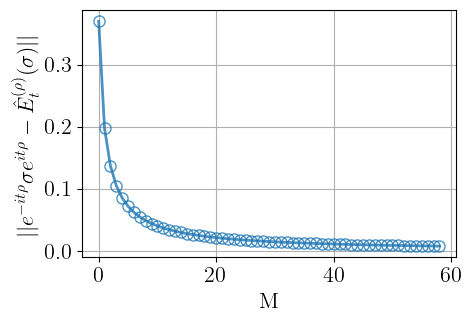

In [ ]:
# Here the DME channel as given in equation (1) is plotted. 
plt.plot(norm_dme,marker='o',markerfacecolor='none',alpha=0.8)
plt.xlabel('M')
plt.ylabel(r'$|| e^{-it\rho}\sigma e^{it\rho} - \hat{E}_t^{(\rho)}(\sigma) ||$')
plt.grid()
plt.savefig(f'DME_norm.pdf')

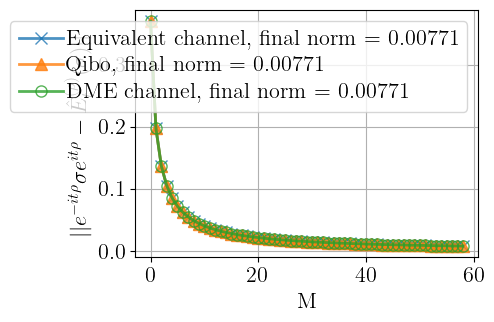

In [ ]:
# To plot other channels calculated above, un-comment the following lines 
# (if they are currently commented)
plt.plot(norm_channel_equivalent,marker='x',alpha=0.8,label=f'Equivalent channel, final norm = {float('%.3g' % norm_channel_equivalent[-1])}')
plt.plot(norm_qibo,marker='^',alpha=0.8,label=f'Qibo, final norm = {float('%.3g' % norm_qibo[-1])}')
plt.plot(norm_dme,marker='o',markerfacecolor='none',alpha=0.8,label=f'DME channel, final norm = {float('%.3g' % norm_dme[-1])}')
plt.xlabel('M')
plt.ylabel(r'$|| e^{-it\rho}\sigma e^{it\rho} - \hat{E}_t^{(\rho)}(\sigma) ||$')
plt.grid()
plt.legend()